In [1]:
from netCDF4 import Dataset #Librería para leer archivos .nc
import numpy as np #Librería para manejo de matrices
import matplotlib.pyplot as plt #Librería para graficar
from mpl_toolkits.basemap import Basemap #Librería para dibujar mapas sobre las gráficas (conda install -c conda-forge Basemap)

### Leer archivos

In [2]:
path = '/home/lucas/Rafa_Output_CHYN/PM2020_Output/PM-2021/Sept21/f.e11.TSVREFC1.f19.fi9.PM-2021_mbsk_sslt_2B21PMon_01fno2/'
nombreArchivo = 'f.e11.TSVREFC1.f19.fi9.PM-2021_mbsk_sslt_2B21PMon_01fno2.cam.h0.0003-00.nc'
archivoNC = Dataset(path+nombreArchivo)
lat = archivoNC.variables['lat'][:].data
lon = archivoNC.variables['lon'][:].data
ozone = archivoNC.variables['O3'][0,:].data
hyam = archivoNC.variables['hyam'][:].data
hybm = archivoNC.variables['hybm'][:].data
ps = archivoNC.variables['PS'][:].data

### Plotear mapas

Text(0.5, 1.0, 'Ozono Superficial')

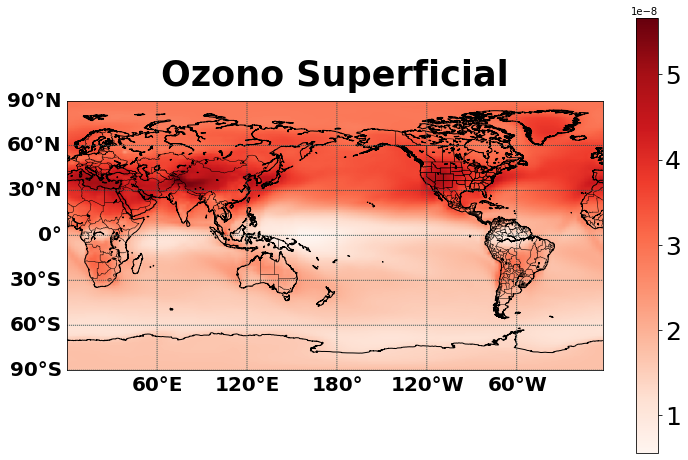

In [6]:
f1 = plt.figure(2,figsize=(12,8)) #Creación de figura donde van a ir las distintas gráficas
ax = f1.add_subplot() #Cuando es una sola gráfica no es necesario, pero cuando son varias gráficas en una figura con esto agregás cada gráfica y las organizas


# m = Basemap(projection='cyl',\  #Proyección a utilizar (cyl=Cilindrica o LatLon)
#             llcrnrlat=lat[0],\ #latitud de la esquina inferior izquierda (Usamos los datos de las variables lat y lon que extragimos del archivo netCDF)
#             urcrnrlat=lat[-1],\ #latitud de la esquina superior derecha
#             llcrnrlon=lon[0],\#longitud de la esquina inferior izquierda
#             urcrnrlon=lon[-1],\ #longitud de la esquina superior derecha
#             resolution='l') #resolución del mapa, las opciones son 'l'=low, 'i'=intermediate , 'f'=full (quizás no funcionen la i y la f y te pide que instales una librería adicional)

#Creamos el mapa de fondo que queremos agregarle a la gráfica (librería Basemap)
m = Basemap(projection='cyl',\
            llcrnrlat=lat[0],\
            urcrnrlat=lat[-1],\
            llcrnrlon=lon[0],\
            urcrnrlon=lon[-1],\
            resolution='l')

m.imshow(ozone[-1,:],cmap='Reds') #ya no se utiliza plt.imshow sino que se utiliza m.imshow (m es la variable o instancia creada por Basemap)

#Funciones para dibujar diferentes lineas en el mapa, prueben comentando y descomentando estas lineas y con distintas resoluciones
m.drawcountries()
m.drawstates()
m.drawcoastlines()
#Funciones para dibujar meridianos y paralelos
parallels = np.arange(-90,120,30) #Que paralelos aparecen (inicio, fin y cada cuántos grados)
meridians = np.arange(60.,360.,60) #Qué meridianos aparecen
m.drawmeridians(meridians,labels=[False,False,False,True],color='darkslategray',fontweight='bold',size=20) #labels es en qué orilla mostrar el texto con los paralelos o los meridianos
m.drawparallels(parallels,labels=[True,False,False,False],color='darkslategray',fontweight='bold',size=20)

#extras de la gráfica, se usa plt
cbar = plt.colorbar()
for t in cbar.ax.get_yticklabels():
     t.set_fontsize(25)
plt.title('Ozono Superficial',fontsize=35, fontweight='bold',pad=15)

### Plotear zonal averages

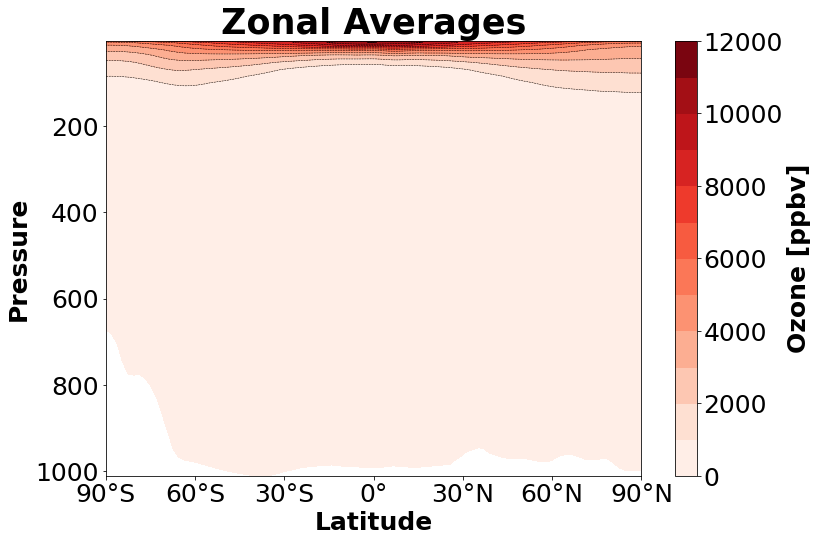

In [4]:
f1 = plt.figure(1,figsize=(12,8))
lons,lats = np.meshgrid(lon,lat) #genera matrices de lats y lons de dos dimensiones para tener el plano latlon que hace falta para graficar más adelante
cantidadNiveles, filas,columnas = ozone.shape #guardo los tamaños de la variable ozone para generar una variable presion
air_pressure = np.zeros((cantidadNiveles, filas,columnas)) #creo una matriz de ceros del mismo tamaño que ozone
#calculo las presiones a partir de las variables hyam hybm y ps
for k in range(cantidadNiveles):
    air_pressure[k,:] = hyam[k]*1e5+hybm[k]*ps[:]
air_pressure = air_pressure/100 #lo paso a hectopascales


ozoneLon = ozone.mean(axis=2)*1e9 #promedio el ozono en el eje de longitud (dimension 2) para tener el zonal average y lo multiplico por 1e9 para tener ppb
presion = air_pressure.mean(axis=2) #lo mismo pero para la presion
lat2 = np.resize(lat,(26,96)) #multiplica la matriz de latitud en el eje de presiones para que quede una nueva matriz de (26,96)
im1 = plt.contourf(lat2,presion,ozoneLon,levels=12,cmap='Reds') #gráfica de niveles de colores
im2 = plt.contour(lat2,presion,ozoneLon,levels=12,colors='k',linewidths=0.5,linestyles='dashed') #lineas que separan niveles de colores

#colorbar y como cambiar el tamaño de la fuente del texto de la colorbar
cbar = plt.colorbar(im1)
for t in cbar.ax.get_yticklabels():
     t.set_fontsize(20)

plt.title('Zonal Averages', fontsize=35,fontweight='bold',loc='center') #titulo principal de la figura
plt.gca().invert_yaxis() #para que las presión 1000 salga abajo en la gráfica
cbar.set_label('Ozone [ppbv]', fontsize=25, fontweight='bold') #label de la colorbar
plt.yticks([1000,800,600,400,200]) #ticks de presion en el eje y
plt.xlabel('Latitude', fontsize=25, fontweight='bold') #texto eje x
plt.ylabel('Pressure', fontsize=25, fontweight='bold') #texto eje y
plt.xticks(range(-90,120,30),['90°S','60°S','30°S','0°','30°N','60°N','90°N']) #rango y texto de los ticks del eje x
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)

plt.savefig('zonal_averages.png',dpi=150) #funcion para guardar la gráfica en un archivo